# Solve the XOR problem
Using keras and sequential layers

## Initialization

In [1]:
import tensorflow as tf
import numpy as np
import scipy
import matplotlib as plt

## Model with cross entropy loss

In [2]:
from tensorflow.keras.layers import Dense
from tensorflow.keras import Sequential

In [3]:
x = [[0.,0.],[1.,1.],[1.,0.],[0.,1.]]
y = [[1.,0.],[1.,0.],[0.,1.],[0.,1.]]
# make 100 copies of the above
for _ in range(1000-1):
    for i in range(4):
        x.append(x[i])
        y.append(y[i])
x = np.array(x, dtype=np.float32)
y = np.array(y, dtype=np.float32)
print(x.shape)

(4000, 2)


In [ ]:
model = Sequential()

# create a regularizer that encourages the network to assign a cost to every weight in the network
# where the cost of each weight is W*l1 + W^2*l2
# this cost is added to the overall loss function

regularizer = tf.keras.regularizers.l1_l2(
    l1=0.01, l2=0.01
)

# let's initialize this model with large random uniform values in the first layer
model.add(Dense(100, activation='tanh', kernel_regularizer=regularizer, kernel_initializer=tf.keras.initializers.random_uniform(minval=-10, maxval=10), name="hidden"))
model.add(Dense(2, activation='softmax', kernel_regularizer=regularizer))

model.compile(loss=tf.keras.metrics.categorical_crossentropy,
              optimizer=tf.keras.optimizers.SGD(0.1),
              metrics=['accuracy'])

## Train model

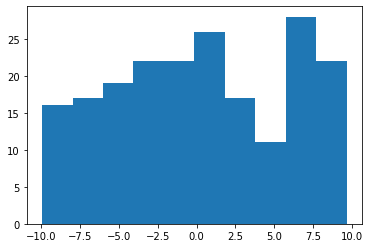

In [ ]:
pred = model.predict_on_batch(x)

def graphHiddenM(model):
    m1 = np.array(model.layers[0].get_weights()[0]).flatten()
    plt.pyplot.hist(x=m1)

# plot the histogram of the values of W in the first layer
graphHiddenM(model)
# notice how the values of W are spread pretty evenly between -10 and 10

125/125 [==============================] - 1s 2ms/step - loss: 57.4403 - accuracy: 0.9860


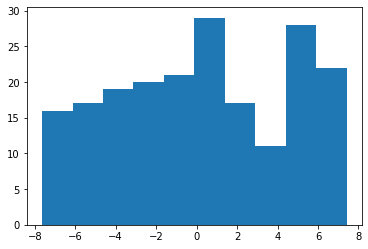

In [ ]:
_ = model.fit(x,y)
graphHiddenM(model)
# notice how the values of W are still spread pretty evenly between -7 and 7 even after 1 epoch of learning

125/125 [==============================] - 0s 2ms/step - loss: 34.6350 - accuracy: 1.0000


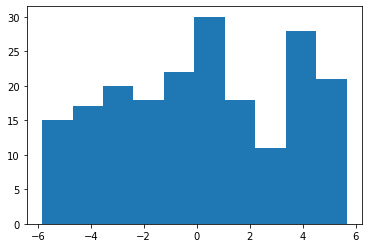

In [ ]:
_ = model.fit(x,y)
graphHiddenM(model)
# and ow between -6 and 6

125/125 [==============================] - 0s 2ms/step - loss: 20.8975 - accuracy: 1.0000


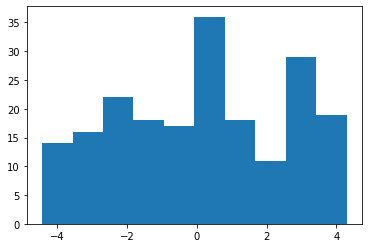

In [ ]:
_ = model.fit(x,y)
graphHiddenM(model)

Epoch 1/5
125/125 [==============================] - 0s 2ms/step - loss: 12.5939 - accuracy: 1.0000
Epoch 2/5
125/125 [==============================] - 0s 2ms/step - loss: 7.5911 - accuracy: 1.0000
Epoch 3/5
125/125 [==============================] - 0s 2ms/step - loss: 4.6089 - accuracy: 1.0000
Epoch 4/5
125/125 [==============================] - 0s 2ms/step - loss: 2.8886 - accuracy: 1.0000
Epoch 5/5
125/125 [==============================] - 0s 2ms/step - loss: 1.9198 - accuracy: 1.0000


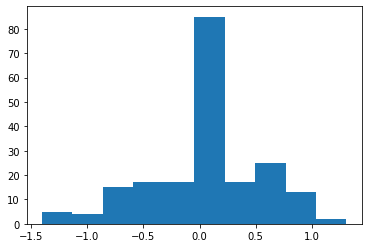

In [ ]:
_ = model.fit(x,y, epochs=5)
graphHiddenM(model)
# and now most of the weights have been set to zero as they are not needed

Epoch 1/5
125/125 [==============================] - 0s 2ms/step - loss: 1.3646 - accuracy: 1.0000
Epoch 2/5
125/125 [==============================] - 0s 2ms/step - loss: 1.0316 - accuracy: 1.0000
Epoch 3/5
125/125 [==============================] - 0s 2ms/step - loss: 0.8275 - accuracy: 1.0000
Epoch 4/5
125/125 [==============================] - 0s 2ms/step - loss: 0.7159 - accuracy: 1.0000
Epoch 5/5
125/125 [==============================] - 0s 2ms/step - loss: 0.6711 - accuracy: 1.0000


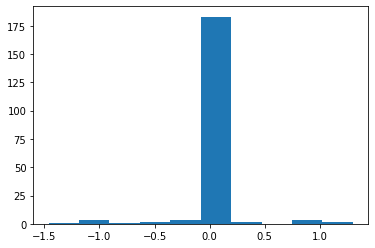

In [ ]:
_ = model.fit(x,y, epochs=5)
graphHiddenM(model)
# notice how the values of W mostly zero, because it turns out we don't need 200 nodes in the first dense layer!
# the cost function is setting weights to zero that are not actively helping

## Show prediction

In [ ]:
print("And the output is...")

pred = model.predict_on_batch(x)

for name,val in zip('truth,predicted'.split(','),[y[:4],pred[:4]]):
    print()
    print(name)
    print(val)


And the output is...

truth
[[1. 0.]
 [1. 0.]
 [0. 1.]
 [0. 1.]]

predicted
[[0.82  0.18 ]
 [0.793 0.207]
 [0.2   0.8  ]
 [0.208 0.792]]


In [ ]:
for layer in model.layers:
    print(layer.name)
    print("M =")
    print(layer.get_weights()[0])
    print("B =")
    print(layer.get_weights()[1])

hidden
M =
[[ 0.001 -0.     0.01  -0.001  0.001  0.     0.001  0.    -0.001 -0.
   0.    -0.001  0.001  0.     0.001 -0.001  0.001  0.     0.     0.
   0.     0.    -0.596  0.001 -0.001  0.001 -0.001 -0.902  0.001  0.001
  -1.172  0.001 -0.    -0.    -0.001  0.     0.001 -0.    -0.127 -0.001
   0.001 -0.082  0.001  0.    -0.001 -0.001 -0.001 -0.001  0.001 -0.
  -0.    -0.     0.001 -0.    -0.001 -0.001 -0.    -0.    -0.001  0.
  -0.001  0.    -0.    -0.     0.001  0.    -0.001 -0.    -0.001  0.001
  -0.001  0.    -0.001 -0.     0.034  0.001 -0.    -0.     0.    -0.
   0.001 -0.    -0.001  0.001  0.    -0.    -0.    -0.     0.233 -1.077
   0.    -0.    -0.    -1.103 -0.001 -0.     1.301  0.001  0.     0.   ]
 [-0.     0.001 -0.001 -0.001 -0.    -0.001  0.001 -0.    -0.001  0.
  -0.001  0.    -0.    -0.001  0.001 -0.     0.001  0.001  0.     0.
   0.09  -0.    -0.627  0.001 -0.001  0.001  0.001  0.781  0.     0.
   1.012 -0.001 -0.001  0.001  0.001  0.     0.001 -0.001 -0.158 -0.
   0.00

In [ ]:
model.predict_on_batch(np.array([[.2,.7]]))

array([[0.6, 0.4]], dtype=float32)

In [ ]:
m1 = model.layers[0].get_weights()[0]
b1 = model.layers[0].get_weights()[1]
m2 = model.layers[1].get_weights()[0]
b2 = model.layers[1].get_weights()[1]

def doit(data):
    r = np.matmul(data,m1) + b1
    r = np.tanh(r)
    r = np.matmul(r,m2) + b2
    r = scipy.special.softmax(r,axis=1)
    return r


In [ ]:
doit([[.2,.7]])

array([[0.6, 0.4]])

In [ ]:
doit(x)

array([[0.82 , 0.18 ],
       [0.793, 0.207],
       [0.2  , 0.8  ],
       ...,
       [0.793, 0.207],
       [0.2  , 0.8  ],
       [0.208, 0.792]], dtype=float32)

(array([3., 0., 1., 0., 0., 0., 1., 0., 0., 5.]),
 array([1. , 1.5, 2. , 2.5, 3. , 3.5, 4. , 4.5, 5. , 5.5, 6. ]),
 <a list of 10 Patch objects>)

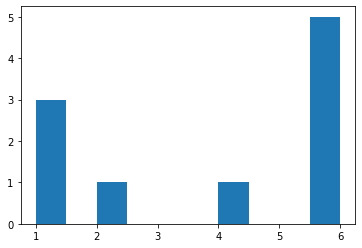

In [ ]:
plt.pyplot.hist(x=[1,1,1,2,4,6,6,6,6,6])